# 04d - Clustering: perfis de mutuários

Agrupar os mutuários pelo perfil de crédito no momento do pedido, sem alvo: o algoritmo junta empréstimos parecidos e a leitura dos grupos é feita depois. O enunciado dá este exemplo: *"borrower clustering (FICO, DTI, credit age, utilization)"*.

São dois algoritmos, o k-means e a mistura de gaussianas (GMM), com o número de grupos a variar de 2 a 10. As medidas de avaliação estão em `src/lending/clustering.py` (`ClusterEvaluator`) e as variáveis e o pré-processamento na classe `BorrowerProfiles` do mesmo módulo.

| Requisito do enunciado | Onde |
|---|---|
| *"Apply at least two clustering algorithms"* | k-means e GMM |
| *"Vary their relevant hyperparameters, including the number of clusters"* | k de 2 a 10; no GMM também o tipo de covariância |
| *"Describe the resulting groups and assess their stability and interpretability"* | Perfis dos grupos e ARI entre sementes e entre amostras |
| *"For clustering, use appropriate internal measures alongside substantive interpretation"* | Cotovelo, silhueta, Davies-Bouldin e Dunn (implementado por nós) |

**Antes de correr:** `01_preprocessamento.ipynb` (gera `aceites_dev.pkl`).

**Ficheiros e tempo de execução.** Cada configuração (algoritmo e número de grupos) é ajustada uma vez e guardada pelo `ClusterGrid`: as medidas em `reports/results/clustering_borrowers.csv` (entra no Git) e o grupo de cada empréstimo em `data/processed/clustering/borrowers/` (fora do Git). Nas execuções seguintes, as configurações já guardadas são lidas em vez de recalculadas. Com `RECALCULAR = True` (no setup), apaga-se tudo e volta-se a calcular do zero.

In [1]:
# Setup: imports e caminhos do projeto
import json
import sys
from pathlib import Path

# Importar o pacote do projeto.
try:
    import lending
except ModuleNotFoundError:
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / "src" / "lending").is_dir():
            sys.path.insert(0, str(parent / "src"))
            break
    import lending

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lending import config
from lending.clustering import PROFILE_LABELS, BorrowerProfiles, ClusterGrid, gmm_spec, kmeans_spec
from lending.plot_style import CATEGORICAL, DIVERGING_CMAP, apply_style
from lending.storage import PickleStore

apply_style()
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)

# True: apaga os resultados guardados das grelhas e volta a calcular tudo (demora minutos)
RECALCULAR = False

## 1. Dados e variáveis

**Coorte.** São os 466 124 empréstimos aceites de 2007-06 a 2014-12 (a coorte do clustering da Parte 1, sem filtros além da limpeza). Ao contrário da classificação, não é preciso conhecer o desfecho, por isso entram também os empréstimos ainda ativos (`Current`). O teste de 2015 nunca é usado: o clustering é descritivo e não tem avaliação final.

**Variáveis do ajuste** (perfil no momento do pedido):

| Variável | O que mede | Porquê |
|---|---|---|
| `fico_range_low` | Pontuação de crédito | Exemplo do enunciado. O `fico_range_high` é sempre `low + 4`: as duas dariam o mesmo valor padronizado e o FICO contaria a dobrar |
| `dti` | Dívidas mensais / rendimento mensal (%) | Exemplo do enunciado |
| `revol_util` | % do limite rotativo em uso | "Utilização" do enunciado |
| `annual_inc` | Rendimento anual | Capacidade financeira |
| `loan_to_income` | Montante pedido / rendimento | Esforço do pedido |
| `revol_to_income` | Saldo rotativo / rendimento | Dívida de cartões face ao rendimento (o `revol_util` não o diz) |
| `open_acc_pct` | % das contas do historial ainda abertas | Crédito recente ou acumulado |
| `credit_history_years` | Anos desde a primeira linha de crédito até à concessão | "Credit age" do enunciado |

A antiguidade do crédito usa o `issue_d` como data de referência. Na tabela de elegibilidade da Fase 1 o `issue_d` estava ❌ no clustering; passou a ⚠️, só como referência desta feature (como já acontecia na classificação).

**Fora do ajuste:** as binárias `ever_delinquent` e `has_public_record` só descrevem os grupos. A taxa de juro, o grau e o desfecho também ficam de fora: são usados depois, para dar significado de negócio aos grupos, e não podem influenciar a sua formação.

In [2]:
data = PickleStore.load(config.ACCEPTED_DEV_PKL, expected_type=pd.DataFrame)
print(f"{len(data):,} empréstimos, {data['issue_d'].min():%Y-%m} a {data['issue_d'].max():%Y-%m}")

profiles = BorrowerProfiles()
original = profiles.table(data)   # unidades originais, antes do pré-processamento

summary = pd.DataFrame({
    "em falta": original.isna().sum(),
    "em falta (%)": (100 * original.isna().mean()).round(3),
    "mínimo": original.min(),
    "p0,5": original.quantile(0.005),
    "mediana": original.median(),
    "p99,5": original.quantile(0.995),
    "máximo": original.max(),
    "assimetria": original.skew(),
}).rename(index=PROFILE_LABELS)
summary.round(2)

466,124 empréstimos, 2007-06 a 2014-12


,em falta,em falta (%),mínimo,"p0,5",mediana,"p99,5",máximo,assimetria
FICO,0,0.00,610.0,660.00,690.00,805.00,845.00,1.24
DTI (%),0,0.00,0.0,0.93,16.87,36.47,39.99,0.19
Utilização rotativa (%),340,0.07,0.0,0.10,57.60,99.20,892.30,-0.16
Rendimento anual (USD),4,0.00,1896.0,15000.00,63000.00,300000.00,7500000.00,29.57
Montante / rendimento,4,0.00,0.0,0.02,0.21,0.49,1.34,0.39
Saldo rotativo / rendimento,4,0.00,0.0,0.00,0.19,1.07,7.96,4.20
Contas abertas (%),31,0.01,0.0,14.71,46.43,100.00,100.00,0.56
Antiguidade do crédito (anos),29,0.01,0.5,3.50,14.50,42.00,70.17,1.07
Já teve atrasos,29,0.01,0.0,0.00,0.00,1.00,1.00,0.15
Tem registo público,29,0.01,0.0,0.00,0.00,1.00,1.00,2.18


**Leitura.**

- **Quase sem valores em falta.** O máximo é o `revol_util`, com 340 (0,07%). As 29 linhas sem antiguidade, atrasos e registos públicos são as mesmas: empréstimos de 2007 sem nenhum dado do *bureau*. A `open_acc_pct` tem mais 2, os casos impossíveis de 2007 (mais contas abertas do que no total).
- **Caudas longas.** O rendimento chega a 7,5 milhões (assimetria 29,6) e o saldo rotativo a 7,96 vezes o rendimento (assimetria 4,2). A utilização rotativa chega a 892%. É isto que o log e o *clipping* tratam.
- **FICO de 610 a 845**, mediana 690. Os 488 empréstimos abaixo de 660 são quase todos (99,6%) *"Does not meet the credit policy"* de 2007–2008.
- **Binárias (só para descrever):** 46,2% dos mutuários já tiveram algum atraso e 13,2% têm pelo menos um registo público.

### Pré-processamento

Os mesmos passos do pipeline da Parte 1, aplicados às 8 variáveis (`BorrowerProfiles.pipeline()`):

1. **Logaritmo no rendimento**, `log(1 + x)`: o rendimento tem uma cauda longa à direita (até 7,5 milhões). Sem o log, os rendimentos altos ficavam muito longe de todos os outros e formavam um grupo só por isso.
2. **Clipping** aos percentis 0,5 e 99,5: os valores mais extremos (ex.: `revol_util` de 892%) passam a ser iguais ao percentil.
3. **Imputação pela mediana**, **sem indicador de "em falta"**. No pipeline da Parte 1, cada coluna com falta ganha uma coluna 0/1. No clustering isso não serve: com 340 em falta (0,07%), o indicador padronizado vale cerca de 37 nessas linhas, uma distância enorme que criaria um grupo "dos que têm o `revol_util` em falta". Com tão poucas faltas, a mediana não muda a forma dos dados.
4. **Padronização** (média 0, desvio 1): a distância euclidiana soma diferenças ao quadrado, por isso sem padronizar o rendimento (dezenas de milhares) esmagava o FICO (centenas) e o DTI (dezenas).

O ajuste é feito em todos os empréstimos do clustering. Não há fuga de informação porque não há conjunto de teste: o clustering descreve estes empréstimos e não é avaliado noutros.

Matriz do clustering: 466,124 x 8, valores em falta: 0


,assimetria antes,assimetria depois,média,desvio
FICO,1.24,1.19,-0.0,1.0
DTI (%),0.19,0.18,-0.0,1.0
Utilização rotativa (%),-0.16,-0.27,-0.0,1.0
Rendimento anual (USD),29.57,0.11,-0.0,1.0
Montante / rendimento,0.39,0.37,0.0,1.0
Saldo rotativo / rendimento,4.20,1.58,0.0,1.0
Contas abertas (%),0.56,0.57,0.0,1.0
Antiguidade do crédito (anos),1.07,0.98,0.0,1.0


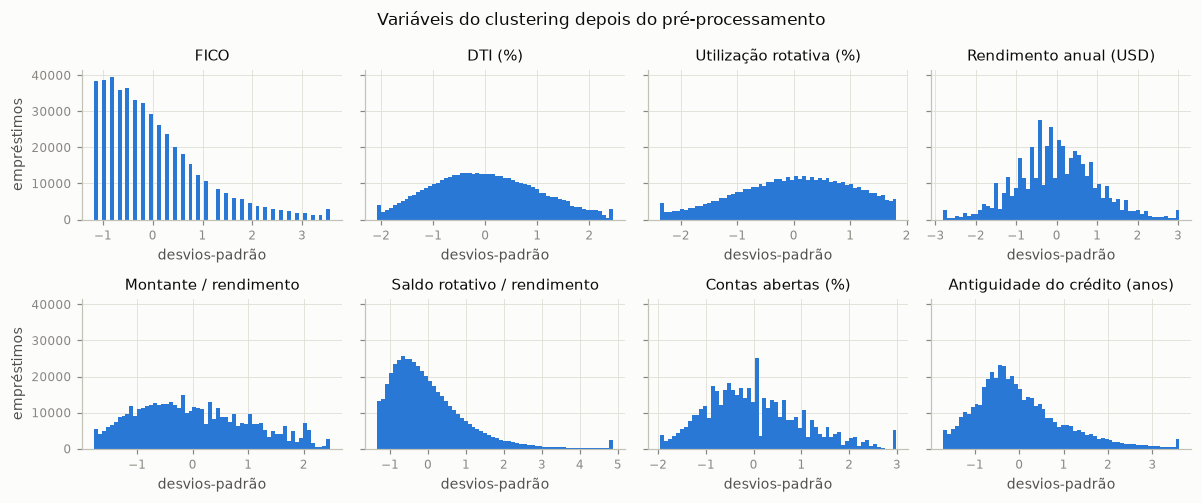

In [3]:
pipeline = profiles.pipeline()
X = pipeline.fit_transform(data[profiles.source_columns()])
print(f"Matriz do clustering: {X.shape[0]:,} x {X.shape[1]}, valores em falta: {int(X.isna().sum().sum())}")

check = pd.DataFrame({
    "assimetria antes": original[profiles.features].skew(),
    "assimetria depois": X.skew(),
    "média": X.mean(),
    "desvio": X.std(ddof=0),
}).rename(index=PROFILE_LABELS)
display(check.round(2))

fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharey=True)
for ax, column in zip(axes.ravel(), profiles.features):
    ax.hist(X[column], bins=60, color=CATEGORICAL[0])
    ax.set_title(PROFILE_LABELS[column])
    ax.set_xlabel("desvios-padrão")
for ax in axes[:, 0]:
    ax.set_ylabel("empréstimos")
fig.suptitle("Variáveis do clustering depois do pré-processamento")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_variaveis.png")
plt.show()

**Leitura.**

- A matriz final não tem valores em falta, e todas as colunas têm média 0 e desvio 1: as 8 variáveis pesam o mesmo na distância.
- **O log resolveu o rendimento:** a assimetria passou de 29,6 para 0,1.
- **O saldo rotativo / rendimento continua com cauda à direita** (assimetria 4,2 → 1,6). A barra isolada a 4,9 desvios são os 2 331 empréstimos (0,5%) presos no limite do *clipping*, com saldo rotativo acima de 1,07 vezes o rendimento. Se aparecer um grupo pequeno só com estes empréstimos, é por causa desta cauda; a coluna `smallest_cluster_pct` das grelhas serve para o detetar. Não se aplicou log a este rácio: `log(1 + x)` quase não muda valores abaixo de 1 (a assimetria só desceria para 1,05) e o *clipping* já limita o extremo.
- **O FICO é discreto** (passos de 5 pontos) e concentrado entre 660 e 720, com cauda à direita.
- As barras nos extremos de quase todas as variáveis são o *clipping*: os 0,5% de cada lado ficam acumulados no limite. Os "pentes" no rendimento vêm de valores redondos declarados (50 000, 60 000 USD).

### Correlações

Na distância euclidiana, duas variáveis muito correlacionadas medem quase a mesma coisa e essa dimensão do perfil conta a dobrar. Uma correlação de Spearman (ordens) acima de 0,8 seria razão para tirar uma das duas.

Maior |rho| entre duas variáveis: 0.41 (Montante / rendimento / Saldo rotativo / rendimento)


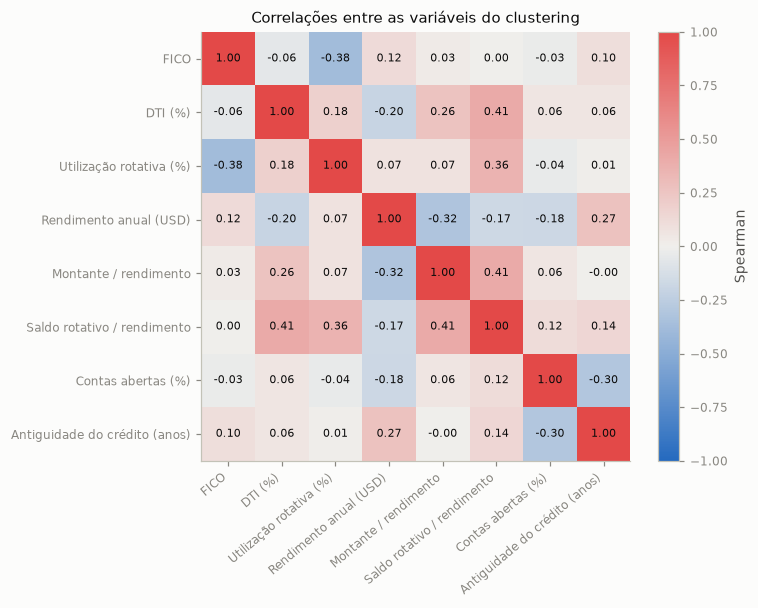

In [4]:
corr = X.corr(method="spearman").rename(index=PROFILE_LABELS, columns=PROFILE_LABELS)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"Maior |rho| entre duas variáveis: {upper.abs().max():.2f} "
      f"({upper.abs().idxmax()[0]} / {upper.abs().idxmax()[1]})")

fig, ax = plt.subplots(figsize=(7, 5.6))
image = ax.imshow(corr, cmap=DIVERGING_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Spearman")
ax.set_title("Correlações entre as variáveis do clustering")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_correlacoes.png")
plt.show()

**Leitura.**

- A maior correlação é 0,41 (montante / rendimento com saldo rotativo / rendimento, e DTI com saldo rotativo / rendimento). Nenhum par passa de 0,8, por isso as 8 variáveis ficam: cada uma acrescenta informação e nenhuma dimensão do perfil conta a dobrar.
- FICO e utilização rotativa: -0,38. É o esperado, porque a utilização do crédito entra no cálculo do FICO.
- Rendimento e montante / rendimento: -0,32, porque o rendimento é o denominador.
- Contas abertas (%) e antiguidade: -0,30. Quem tem um historial longo acumulou contas já fechadas.
- Com correlações tão fracas, não há razão para reduzir a dimensão (PCA) antes do clustering. A PCA fica só para desenhar os grupos.

### Composição no tempo

O clustering junta oito anos de empréstimos. Se a população mudou muito, os grupos podem refletir os anos em vez de perfis de mutuário.

In [5]:
year = data["issue_d"].dt.year.rename("ano")
by_year = original[profiles.features].groupby(year).median().rename(columns=PROFILE_LABELS)
by_year.insert(0, "% dos empréstimos", (100 * year.value_counts(normalize=True).sort_index()).round(1))
by_year.insert(0, "empréstimos", year.value_counts().sort_index())
by_year.round(2)

,empréstimos,% dos empréstimos,FICO,DTI (%),Utilização rotativa (%),Rendimento anual (USD),Montante / rendimento,Saldo rotativo / rendimento,Contas abertas (%),Antiguidade do crédito (anos)
ano,,,,,,,,,,
2007,603,0.1,680.0,10.00,48.1,50000.0,0.14,0.11,58.33,8.17
2008,2388,0.5,690.0,13.10,49.5,52529.5,0.14,0.18,50.00,11.00
2009,5280,1.1,710.0,12.60,44.4,57000.0,0.15,0.16,46.43,11.58
2010,12532,2.7,710.0,13.24,48.8,57996.0,0.16,0.15,43.95,12.33
2011,21709,4.7,710.0,13.92,51.5,60000.0,0.17,0.16,43.59,12.92
2012,53334,11.4,695.0,16.48,61.0,60000.0,0.20,0.20,47.06,13.33
2013,134767,28.9,690.0,16.89,60.3,64000.0,0.21,0.21,46.67,14.50
2014,235511,50.5,685.0,17.62,56.3,65000.0,0.21,0.19,46.67,15.17


**Leitura.**

- **2013 e 2014 têm 79,4% dos empréstimos** (só 2014 tem 50,5%), e 2007–2011 juntos têm 9,1%. Os grupos vão descrever sobretudo os mutuários de 2013–2014. Não se pondera nem se reamostra por ano: o objetivo é descrever os mutuários que a LendingClub financiou, e esses são, na maioria, dos últimos anos.
- **A população mudou:** o DTI mediano subiu de 10 (2007) para 17,6 (2014), a utilização rotativa passou de 44–52% (até 2011) para 56–61% (a partir de 2012) e a antiguidade do crédito de 8 para 15 anos. O FICO mediano subiu para 710 em 2009–2011 e voltou a descer para 685 em 2014.
- **Consequência:** um grupo pode juntar sobretudo empréstimos de um período (ex.: DTI baixo e historial curto, típico dos primeiros anos) em vez de um tipo de mutuário. Para o verificar, cada grupo vai ter a sua distribuição por ano e a estabilidade compara grupos ajustados em 2007–2012 e em 2013–2014. Isto responde ao pedido do enunciado de discutir a mudança temporal (*"temporal change"*).

## 2. k-means

**Como funciona** (algoritmo de Lloyd):

1. Escolhe k centros iniciais com o k-means++, que espalha os centros: cada novo centro tende a ficar longe dos anteriores.
2. Atribui cada empréstimo ao centro mais próximo (distância euclidiana).
3. Move cada centro para a média dos empréstimos que lhe ficaram atribuídos.
4. Repete 2 e 3 até os grupos deixarem de mudar.

Cada iteração faz descer a WSS (soma das distâncias ao quadrado de cada ponto ao seu centro), por isso o algoritmo converge, mas para um mínimo local que depende do início. Com `n_init=10` corre 10 inícios diferentes e fica o de menor WSS. O k-means supõe grupos "redondos" e de tamanho parecido, porque só olha para a distância ao centro.

**Grelha:** k de 2 a 10, nos 466 124 empréstimos, `n_init=10`, semente 42 (`kmeans_spec()`).

**Como ler as medidas** (calculadas pelo `ClusterEvaluator` nos mesmos pontos para todos os k):

| Medida | Melhor | Nota |
|---|---|---|
| WSS (cotovelo) | O k a partir do qual a descida deixa de compensar | Desce sempre com k, por isso não se escolhe o mínimo |
| Silhueta | Mais alta (máximo 1) | Amostra de 20 000 pontos |
| Davies-Bouldin | Mais baixo (mínimo 0) | Todos os pontos |
| Dunn | Mais alto | Amostra de 5 000 pontos; medida de pior caso |
| Grupo mais pequeno (%) | - | Deteta grupos minúsculos feitos de valores extremos |

In [6]:
grid = ClusterGrid("borrowers")
results = grid.run(X, [kmeans_spec()], recompute=RECALCULAR)

kmeans = results[results["model"] == "k-means"].copy()
kmeans["k"] = kmeans["params"].map(lambda p: json.loads(p)["n_clusters"])
kmeans = kmeans.sort_values("k").set_index("k")
# Quanto desce a WSS em relação ao k anterior (ajuda a ler o cotovelo)
kmeans["descida da WSS (%)"] = 100 * (1 - kmeans["wss"] / kmeans["wss"].shift())

kmeans_table = kmeans[["wss", "descida da WSS (%)", "silhouette", "davies_bouldin", "dunn",
                       "smallest_cluster_pct", "n_iter", "fit_seconds"]].rename(columns={
    "wss": "WSS", "silhouette": "silhueta", "davies_bouldin": "Davies-Bouldin",
    "smallest_cluster_pct": "grupo mais pequeno (%)", "n_iter": "iterações",
    "fit_seconds": "tempo de ajuste (s)"})
kmeans_table.round({"WSS": 0, "descida da WSS (%)": 1, "silhueta": 3, "Davies-Bouldin": 3,
                    "dunn": 4, "grupo mais pequeno (%)": 1, "tempo de ajuste (s)": 1})

,WSS,descida da WSS (%),silhueta,Davies-Bouldin,dunn,grupo mais pequeno (%),iterações,tempo de ajuste (s)
k,,,,,,,,
2,3123246.0,NaN,0.151,2.166,0.0505,48.9,13,0.9
3,2781551.0,10.9,0.145,1.983,0.0450,20.7,15,1.3
4,2506657.0,9.9,0.142,1.783,0.0587,16.2,13,1.6
5,2365442.0,5.6,0.133,1.892,0.0421,12.6,28,3.6
6,2248870.0,4.9,0.125,1.883,0.0550,11.1,42,3.1
7,2150184.0,4.4,0.118,1.888,0.0364,8.7,79,4.4
8,2065886.0,3.9,0.114,1.822,0.0368,6.5,121,6.0
9,1997384.0,3.3,0.113,1.789,0.0363,6.4,43,4.7
10,1936017.0,3.1,0.113,1.768,0.0381,6.1,130,5.8


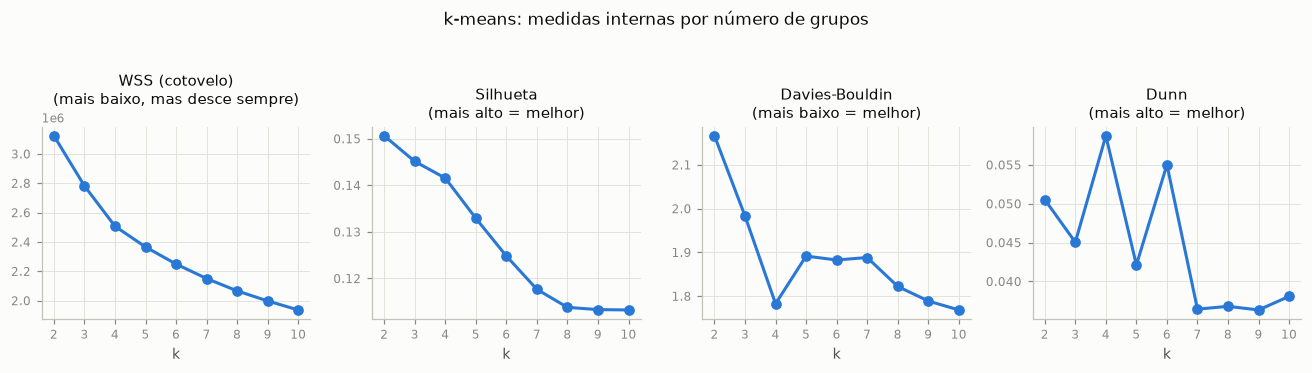

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
panels = [("wss", "WSS (cotovelo)", "mais baixo, mas desce sempre"),
          ("silhouette", "Silhueta", "mais alto = melhor"),
          ("davies_bouldin", "Davies-Bouldin", "mais baixo = melhor"),
          ("dunn", "Dunn", "mais alto = melhor")]
for ax, (column, title, note) in zip(axes, panels):
    ax.plot(kmeans.index, kmeans[column], marker="o", color=CATEGORICAL[0])
    ax.set_title(f"{title}\n({note})")
    ax.set_xlabel("k")
    ax.set_xticks(kmeans.index)
axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
fig.suptitle("k-means: medidas internas por número de grupos", y=1.04)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_kmeans.png", bbox_inches="tight")
plt.show()

Tamanho dos grupos de cada k (em % dos empréstimos, do maior para o mais pequeno). Um grupo muito pequeno pode ser só a cauda de uma variável e não um tipo de mutuário.

In [8]:
sizes = {}
for k, row in kmeans.iterrows():
    labels = grid.labels("k-means", row["config_id"])
    sizes[k] = sorted(100 * np.bincount(labels) / len(labels), reverse=True)
sizes = pd.DataFrame.from_dict(sizes, orient="index")
sizes.columns = [f"{i}.º" for i in range(1, sizes.shape[1] + 1)]
sizes.index.name = "k"
sizes.round(1).fillna("")

,1.º,2.º,3.º,4.º,5.º,6.º,7.º,8.º,9.º,10.º
k,,,,,,,,,,
2,51.1,48.9,,,,,,,,
3,41.1,38.2,20.7,,,,,,,
4,32.5,27.5,23.9,16.2,,,,,,
5,29.5,24.5,18.5,14.9,12.6,,,,,
6,24.1,22.8,17.2,13.6,11.2,11.1,,,,
7,21.2,19.1,15.6,14.6,11.2,9.6,8.7,,,
8,16.6,15.4,14.9,13.8,13.1,10.7,8.9,6.5,,
9,13.9,13.9,13.9,11.8,11.6,10.5,9.9,8.2,6.4,
10,13.2,12.8,12.3,11.4,11.2,9.0,8.7,7.8,7.5,6.1


**Leitura.**

- **Cotovelo em k = 4.** A WSS desce 10,9% de k = 2 para 3 e 9,9% de 3 para 4. A partir daí a descida cai para metade (5,6% de 4 para 5) e continua a diminuir (3% a 5% por cada grupo a mais): cada grupo depois do 4.º explica pouco mais.
- **O Davies-Bouldin e o Dunn também apontam para k = 4.** O Davies-Bouldin tem um mínimo local em k = 4 (1,78, contra 1,88-1,89 em k = 5 a 7; só volta a esse nível em k = 10) e o Dunn é máximo em k = 4 (0,059). O Dunn oscila (0,042 em k = 5, 0,055 em k = 6) porque depende de um único par de pontos e de um único diâmetro, por isso serve de apoio e não decide sozinho.
- **A silhueta prefere k = 2** (0,151) e desce sempre com k, mas a diferença até k = 4 é pequena (0,142). E k = 2 só divide os empréstimos ao meio (51% / 49%), o que descreve pouco.
- **A estrutura é fraca.** As silhuetas, de 0,11 a 0,15, ficam abaixo de 0,25, o valor abaixo do qual se considera que não há estrutura substancial (Kaufman e Rousseeuw). O Dunn de 0,04 a 0,06 diz o mesmo: há sempre empréstimos de grupos diferentes quase colados. Os perfis de crédito formam um contínuo, sem grupos naturalmente separados, e o k-means faz uma segmentação desse contínuo. Os grupos continuam a servir, mas lêem-se como regiões do espaço dos perfis, com fronteiras convencionais; o seu valor está na estabilidade e na interpretação (passos seguintes), não na separação.
- **Nenhum grupo minúsculo.** O mais pequeno tem 16,2% dos empréstimos em k = 4 e nunca menos de 6,1% (k = 10). A cauda do saldo rotativo / rendimento (2 331 empréstimos no limite do *clipping*) não formou um grupo próprio.
- **Tempo:** 1 a 6 s por ajuste nos 466 124 empréstimos e cerca de 5 s de avaliação por k (quase tudo na silhueta). As iterações sobem de 13 para 130 com k: com mais grupos, as fronteiras passam por zonas densas e os centros demoram mais a estabilizar.

**Candidato: k = 4.** A escolha final fica para depois do GMM e da estabilidade.

## 3. Mistura de gaussianas (GMM)

**Como funciona.** Supõe que os dados vêm de k distribuições normais multivariadas (as componentes), cada uma com a sua média, a sua matriz de covariância e o seu peso (a fração dos dados que lhe pertence). Ajusta-se com o algoritmo EM (*expectation-maximization*):

1. **E:** com os parâmetros atuais, calcula a probabilidade de cada empréstimo pertencer a cada componente.
2. **M:** reestima as médias, as covariâncias e os pesos como médias ponderadas por essas probabilidades.
3. Repete até a verosimilhança deixar de subir.

O EM começa nos centros de um k-means e, como o k-means, só garante um ótimo local: `n_init=3` corre 3 inícios e fica o de maior verosimilhança.

**Diferenças face ao k-means:**
- **atribuição suave:** cada empréstimo tem uma probabilidade por grupo, e o grupo final é o mais provável;
- **grupos elípticos e de tamanhos diferentes,** porque cada componente tem a sua covariância. O k-means é o caso limite de um GMM com covariâncias esféricas iguais e atribuição "dura".

**Grelha** (`gmm_spec()`): k de 2 a 10 x tipo de covariância.
- `full`: matriz completa, ou seja, elipses com qualquer orientação (as variáveis podem estar correlacionadas dentro do grupo). São 8 médias + 36 covariâncias por grupo.
- `diag`: só as variâncias, ou seja, elipses alinhadas com os eixos. São 8 médias + 8 variâncias por grupo.

O ajuste usa os 466 124 empréstimos. Num teste, o maior ajuste (`full`, k = 10) demorou cerca de 35 s, por isso não foi preciso a amostra de 100 000 que o plano previa.

**Medidas próprias do GMM:**
- **BIC** = -2 log L + p log n (L = verosimilhança, p = número de parâmetros, n = pontos). Premeia o ajuste e penaliza a complexidade; mais baixo = melhor. O AIC usa 2p em vez de p log n.
- **Certeza da atribuição:** média da probabilidade do grupo atribuído. Perto de 1, os grupos estão bem separados; perto de 1/k, a atribuição é quase ao acaso.

A silhueta, o Davies-Bouldin e o Dunn são calculados sobre o grupo mais provável, nos mesmos pontos que no k-means, por isso os dois algoritmos são diretamente comparáveis.

In [9]:
# O RECALCULAR já foi aplicado na secção 2 (apaga a grelha toda, incluindo o GMM)
results = grid.run(X, [gmm_spec()])

gmm = results[results["model"] == "GMM"].copy()
params = gmm["params"].map(json.loads)
gmm["k"] = params.map(lambda p: p["n_components"])
gmm["covariância"] = params.map(lambda p: p["covariance_type"])
gmm = gmm.sort_values(["covariância", "k"]).set_index(["covariância", "k"])

gmm_table = gmm[["wss", "silhouette", "davies_bouldin", "dunn", "bic", "mean_max_proba",
                 "smallest_cluster_pct", "n_iter", "converged", "fit_seconds"]].rename(columns={
    "wss": "WSS", "silhouette": "silhueta", "davies_bouldin": "Davies-Bouldin",
    "bic": "BIC", "mean_max_proba": "certeza", "smallest_cluster_pct": "grupo mais pequeno (%)",
    "n_iter": "iterações", "converged": "convergiu", "fit_seconds": "tempo de ajuste (s)"})
gmm_table.round({"WSS": 0, "silhueta": 3, "Davies-Bouldin": 3, "dunn": 4, "BIC": 0, "certeza": 3,
                 "grupo mais pequeno (%)": 1, "tempo de ajuste (s)": 1})

[borrowers] GMM {'covariance_type': 'full', 'n_components': 2} | silhueta 0.118 | 8.4 s


[borrowers] GMM {'covariance_type': 'full', 'n_components': 3} | silhueta 0.107 | 21.3 s


[borrowers] GMM {'covariance_type': 'full', 'n_components': 4} | silhueta 0.087 | 27.5 s


[borrowers] GMM {'covariance_type': 'full', 'n_components': 5} | silhueta 0.066 | 38.5 s


[borrowers] GMM {'covariance_type': 'full', 'n_components': 6} | silhueta 0.053 | 54.0 s


[borrowers] GMM {'covariance_type': 'full', 'n_components': 7} | silhueta 0.040 | 67.8 s


... (9 outputs left out)

[borrowers] GMM {'covariance_type': 'diag', 'n_components': 8} | silhueta 0.065 | 26.7 s


[borrowers] GMM {'covariance_type': 'diag', 'n_components': 9} | silhueta 0.063 | 34.1 s


[borrowers] GMM {'covariance_type': 'diag', 'n_components': 10} | silhueta 0.068 | 31.1 s


WSS  silhueta  Davies-Bouldin    dunn         BIC  \
covariância k                                                             
diag        2   3158907.0     0.141           2.247  0.0499  10189829.0   
            3   2903907.0     0.104           2.276  0.0391   9999601.0   
            4   2620467.0     0.108           2.034  0.0335   9855224.0   
            5   2482784.0     0.106           2.117  0.0336   9789811.0   
            6   2413629.0     0.086           2.194  0.0386   9732773.0   
            7   2343723.0     0.073           2.133  0.0485   9678079.0   
            8   2268673.0     0.065           2.085  0.0336   9654844.0   
            9   2223781.0     0.063           2.229  0.0305   9607243.0   
            10  2142157.0     0.068           2.191  0.0336   9584785.0   
full        2   3250950.0     0.118           2.467  0.0499   9812905.0   
            3   3037988.0     0.107           2.468  0.0314   9612665.0   
            4   2818670.0     0.087           2.235  0.0361   9535663.0   
            5   2725313.0     0.066           2.429  0.0460   9490280.0   
            6   2664324.0     0.053           2.503  0.0361   9447627.0   
            7   2584584.0     0.040           2.567  0.0444   9425898.0   
            8   2376500.0     0.060           2.276  0.0424   9424617.0   
            9   2388593.0     0.044           2.436  0.0279   9379045.0   
            10  2367031.0     0.034           2.388  0.0361   9358904.0   

                certeza  grupo mais pequeno (%)  iterações convergiu  \
covariância k                                                          
diag        2     0.896                    49.4          6      True   
            3     0.843                    30.5         15      True   
            4     0.830                    16.4         13      True   
            5     0.812                    12.4         11      True   
            6     0.789                    11.1         16      True   
            7     0.784                     8.4         30      True   
            8     0.760                     8.1         28      True   
            9     0.754                     7.3         51      True   
            10    0.744                     6.2         26      True   
full        2     0.857                    44.6         10      True   
            3     0.853                    18.9         33      True   
            4     0.804                    14.7         20      True   
            5     0.767                    13.2         24      True   
            6     0.750                    11.0         32      True   
            7     0.727                     7.9         41      True   
            8     0.721                     8.1         19      True   
            9     0.705                     7.0         31      True   
            10    0.687                     5.7         31      True   

                tempo de ajuste (s)  
covariância k                        
diag        2                   3.3  
            3                   7.4  
            4                   8.5  
            5                   8.3  
            6                  14.6  
            7                  25.4  
            8                  26.7  
            9                  34.1  
            10                 31.1  
full        2                   8.4  
            3                  21.4  
            4                  27.6  
            5                  38.5  
            6                  54.0  
            7                  67.8  
            8                  50.1  
            9                  69.8  
            10                 96.1

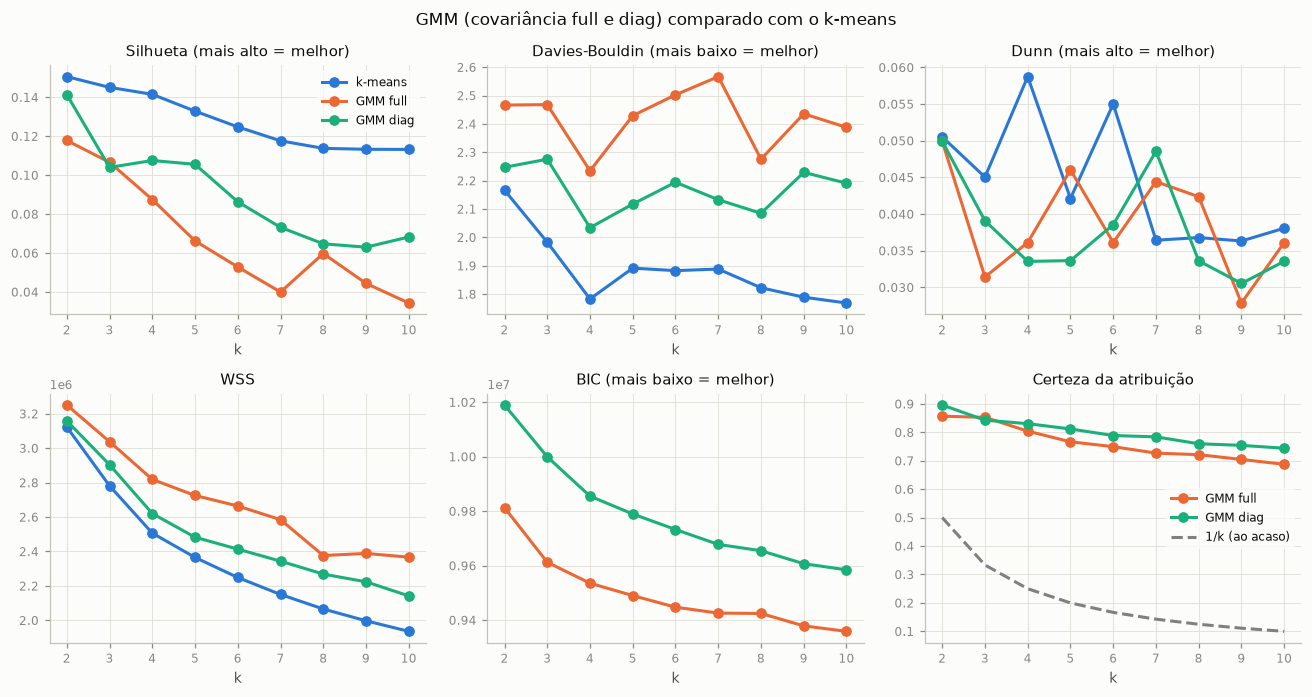

In [10]:
series = {"k-means": kmeans, "GMM full": gmm.loc["full"], "GMM diag": gmm.loc["diag"]}
panels = [("silhouette", "Silhueta (mais alto = melhor)"),
          ("davies_bouldin", "Davies-Bouldin (mais baixo = melhor)"),
          ("dunn", "Dunn (mais alto = melhor)"),
          ("wss", "WSS"),
          ("bic", "BIC (mais baixo = melhor)"),
          ("mean_max_proba", "Certeza da atribuição")]

fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for ax, (column, title) in zip(axes.ravel(), panels):
    for (name, frame), color in zip(series.items(), CATEGORICAL):
        if column in frame and frame[column].notna().any():
            ax.plot(frame.index, frame[column], marker="o", color=color, label=name)
    ax.set_title(title)
    ax.set_xlabel("k")
    ax.set_xticks(range(2, 11))
ks = np.arange(2, 11)
axes[1, 2].plot(ks, 1 / ks, linestyle="--", color="grey", label="1/k (ao acaso)")
axes[1, 2].legend()
axes[0, 0].legend()
for ax in (axes[1, 0], axes[1, 1]):
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
fig.suptitle("GMM (covariância full e diag) comparado com o k-means")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_gmm.png")
plt.show()

**Leitura.**

- **O BIC desce sempre com k**, nas duas covariâncias (de 9,81 para 9,36 milhões no `full`), por isso não escolhe o número de grupos. Com 466 124 pontos, a penalização p log n (log n ≈ 13 por parâmetro) é pequena face ao ganho de verosimilhança de cada componente nova. E os dados não são uma mistura de normais (FICO discreto, picos do *clipping*, caudas): cada componente nova "remenda" um desvio à normalidade. O que o BIC mostra com clareza é que o **`full` é sempre melhor do que o `diag`** (BIC cerca de 4% mais baixo em todos os k): as variáveis estão correlacionadas dentro dos grupos e as elipses inclinadas descrevem-nas melhor.
- **Nas medidas internas, o k-means ganha em todos os k** (silhueta 0,142 contra 0,108 no `diag` e 0,087 no `full`, em k = 4). Não quer dizer que o GMM seja pior: a silhueta, o Davies-Bouldin e a WSS usam a distância euclidiana e premeiam grupos compactos e "redondos", que é exatamente o que o k-means otimiza. O GMM `full` cria componentes largas e inclinadas, que se sobrepõem às outras, e por isso perde mais nestas medidas.
- **k = 4 volta a destacar-se:** o Davies-Bouldin tem um mínimo local em k = 4 nos três algoritmos (k-means 1,78, `diag` 2,03, `full` 2,24). No `diag`, a silhueta tem um patamar em k = 4-5 (0,108 e 0,106) depois da descida de k = 2 para 3.
- **O Dunn não distingue nada:** fica entre 0,03 e 0,05 em todos os casos e oscila sem padrão (é uma medida de pior caso, numa amostra).
- **Certeza da atribuição em k = 4:** 0,83 no `diag` e 0,80 no `full`, muito acima de 1/k = 0,25. Em média, cada empréstimo tem cerca de 80% de probabilidade no seu grupo: os grupos sobrepõem-se (coerente com a silhueta baixa), mas a maioria dos empréstimos tem um grupo claro. A certeza desce com k, porque grupos mais pequenos partilham mais fronteiras.
- **Sem problemas numéricos:** os 18 ajustes convergiram e o grupo mais pequeno nunca tem menos de 5,7%.
- **Tempo:** 3 a 96 s por ajuste (com 3 inícios cada), cerca de 10 minutos para a grelha inteira na primeira execução; nas seguintes, a grelha é lida do CSV.

**Para o passo seguinte:** k = 4 é o candidato nos dois algoritmos. Falta ver se o k-means e o GMM chegam aos **mesmos** grupos (ARI entre algoritmos) e escolher a configuração final.